# code_195 · Diagnosis should produce a new independent experiment

**Book:** section 36.8. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_195).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7795;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7795


<a id="diagnostic-audit-before-revision"></a>
 ## Distinguish label defects, timing defects and missing support
 Source, diagnostic and final cohorts contain 200, 80 and 100 independent buildings, each with four records. Source has only 5% new material and loads below 1; new-material source loads are below 0.5. Diagnostic/final cohorts contain 45% new material and loads to 1.8. Burden follows 2×load+0.5×sensor+3×new_material×load² plus building and record noise. A verified source unit flag marks 5% labels recorded in hundredths of the declared unit. A post-outcome inspection field closely follows source outcomes but is random in later cohorts: its timestamp excludes it from a deployable predictor.

 Fit an intentionally defective Ridge with recorded labels and the post-outcome field; inspect diagnostic errors. Apply only deterministic unit conversion supported by the source audit flag, remove the forbidden field, then fit a fixed 120-iteration depth-three histogram model on legitimate source inputs. Diagnostic observations identify where errors concentrate; they are not subsequently treated as independent final confirmation. The audit knows recorded unit metadata, not a general ability to identify bad labels from a large residual.


,material,load_above_source_range,records,buildings,defective_RMSE,clean_source_RMSE
0,0,False,96,38,5.245369,0.245731
1,0,True,60,31,5.635228,1.007513
2,1,False,79,38,6.195661,1.416717
3,1,True,85,38,8.795145,7.643184


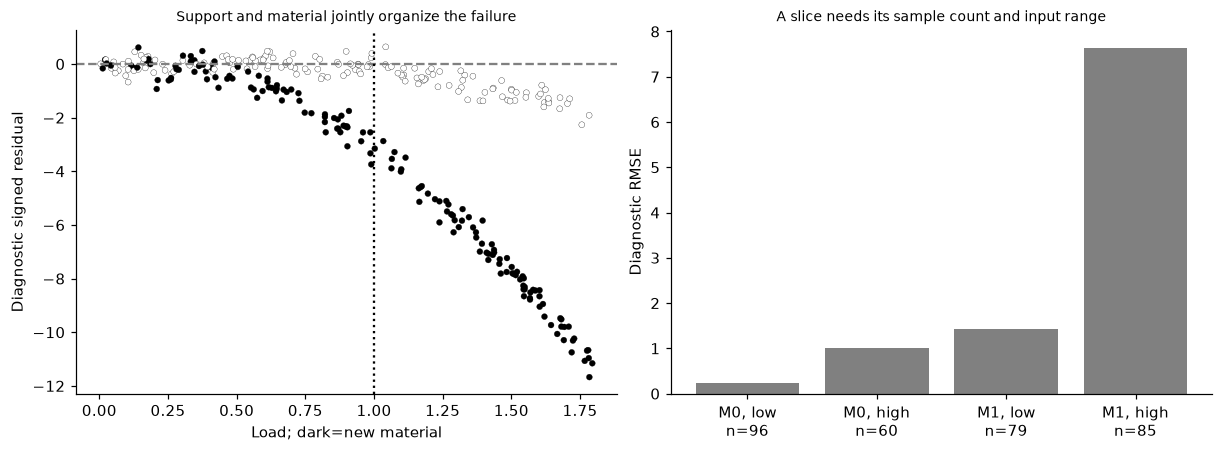

In [2]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
def cohort(n,source=False):
    group=np.repeat(np.arange(n),4);material=rng.binomial(1,.05 if source else .45,n)[group];load=rng.uniform(0,1 if source else 1.8,n*4)
    if source:load[material==1]*=.5
    sensor=rng.normal(size=n*4);x=np.c_[load,sensor,material];y=2*load+.5*sensor+3*material*load**2+rng.normal(scale=.25,size=n)[group]+rng.normal(scale=.1,size=n*4);return x,y,group
xs,true_s,gs=cohort(200,True);xd,yd,gd=cohort(80);xf,yf,gf=cohort(100);unit_flag=rng.random(len(xs))<.05;recorded=true_s*np.where(unit_flag,100,1);post_source=true_s+rng.normal(scale=.05,size=len(xs));post_diag=rng.normal(size=len(xd));bad=Ridge(alpha=1).fit(np.c_[xs,post_source],recorded);bad_diag=bad.predict(np.c_[xd,post_diag]);corrected=recorded/np.where(unit_flag,100,1);assert np.allclose(corrected,true_s);assert xs[xs[:,2]==1,0].max()<.5
def fit(x,y):return HistGradientBoostingRegressor(max_iter=120,max_depth=3,learning_rate=.08,min_samples_leaf=12,early_stopping=False,random_state=SEED).fit(x,y)
clean=fit(xs,corrected);clean_diag=clean.predict(xd);diag_rows=[]
for material in [0,1]:
    for high in [False,True]:
        mask=(xd[:,2]==material)&((xd[:,0]>1)==high);diag_rows.append({'material':material,'load_above_source_range':high,'records':int(mask.sum()),'buildings':int(len(np.unique(gd[mask]))),'defective_RMSE':float(np.sqrt(np.mean((bad_diag[mask]-yd[mask])**2))),'clean_source_RMSE':float(np.sqrt(np.mean((clean_diag[mask]-yd[mask])**2)))})
assert sum(r['records'] for r in diag_rows)==320;RESULTS.update(source_buildings=200,diagnostic_buildings=80,final_buildings=100,source_verified_unit_conversions=int(unit_flag.sum()),post_outcome_feature_removed=True,diagnostic_slices=diag_rows,defective_diagnostic_RMSE=float(np.sqrt(np.mean((bad_diag-yd)**2))),clean_diagnostic_RMSE=float(np.sqrt(np.mean((clean_diag-yd)**2))))
display(pd.DataFrame(diag_rows));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].scatter(xd[:,0],clean_diag-yd,c=xd[:,2],cmap='Greys',edgecolors='black',linewidths=.2,s=15);axes[0].axhline(0,color='.5',linestyle='--');axes[0].axvline(1,color='black',linestyle=':');axes[0].set(xlabel='Load; dark=new material',ylabel='Diagnostic signed residual',title='Support and material jointly organize the failure');xx=np.arange(4);axes[1].bar(xx,[r['clean_source_RMSE'] for r in diag_rows],color='.5');axes[1].set(xticks=xx,xticklabels=[f'M{r["material"]}, {"high" if r["load_above_source_range"] else "low"}\nn={r["records"]}' for r in diag_rows],ylabel='Diagnostic RMSE',title='A slice needs its sample count and input range');plt.show()


<a id="targeted-new-source-and-final-assessment"></a>
 ## Acquire new source observations for the identified regime
 After inspecting diagnostic errors, acquire 80 genuinely new buildings with the new material, loads 0.8–1.8 and four observations each under the same generated law. This is independent source acquisition, not relabelling the diagnostic set as training or collecting final outcomes. Keep the clean model recipe fixed and fit it with source plus these 320 new records. Freeze both clean-source and augmented models, then assess both once on the 100 locked final buildings. Report overall and material/load slices with counts. This experiment changes available source support; it does not prove that adding data always helps or that the simulator's material law is correct. Final errors are reported without another tuning cycle.


,slice,records,buildings,Clean source,Added source
0,All,400,100,3.011554,2.724976
1,Common material,224,56,0.614856,3.630669
2,"New material, load≤1",99,42,1.259233,0.356808
3,"New material, load>1",77,36,6.631408,0.251737


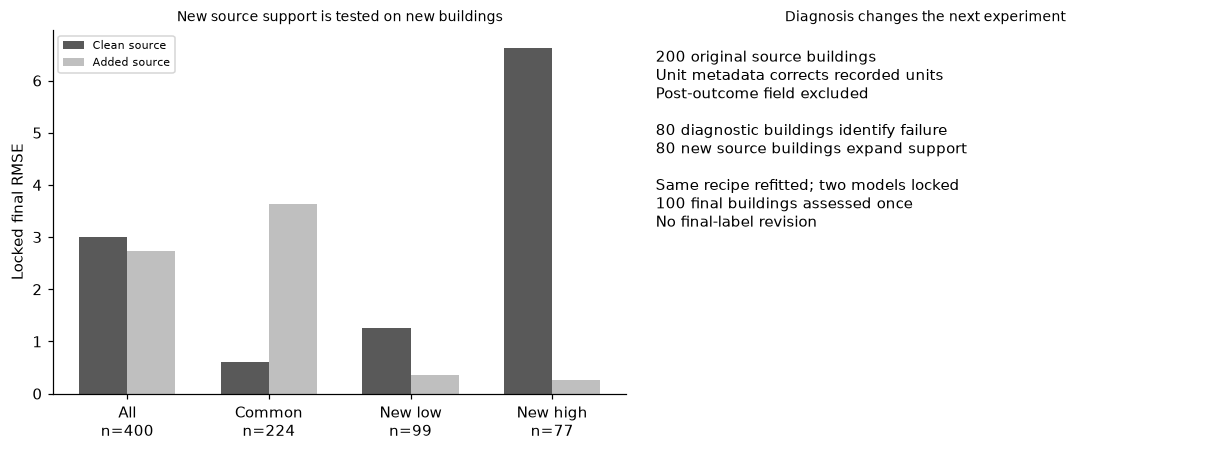

In [3]:
added_buildings=80;ga=np.repeat(np.arange(added_buildings),4);la=rng.uniform(.8,1.8,320);sa=rng.normal(size=320);xa=np.c_[la,sa,np.ones(320)];ya=2*la+.5*sa+3*la**2+rng.normal(scale=.25,size=80)[ga]+rng.normal(scale=.1,size=320);augmented=fit(np.r_[xs,xa],np.r_[corrected,ya]);locked={'Clean source':clean.predict(xf),'Added source':augmented.predict(xf)};final_rows=[]
masks=[('All',np.ones(400,bool)),('Common material',xf[:,2]==0),('New material, load≤1',(xf[:,2]==1)&(xf[:,0]<=1)),('New material, load>1',(xf[:,2]==1)&(xf[:,0]>1))]
for label,mask in masks:
    final_rows.append({'slice':label,'records':int(mask.sum()),'buildings':int(len(np.unique(gf[mask]))),**{name:float(np.sqrt(np.mean((p[mask]-yf[mask])**2))) for name,p in locked.items()}})
assert len(xa)==320 and len(xf)==400;assert np.all(xa[:,2]==1);assert sum(r['records'] for r in final_rows[1:])==400;RESULTS.update(added_source_buildings=80,added_source_records=320,final_scores=final_rows,diagnostic_records_used_for_fitting=0,final_records_used_for_fitting_or_selection=0,unchanged_clean_model_recipe=True);display(pd.DataFrame(final_rows));fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(4);axes[0].bar(xx-.17,[r['Clean source'] for r in final_rows],width=.34,color='.35',label='Clean source');axes[0].bar(xx+.17,[r['Added source'] for r in final_rows],width=.34,color='.75',label='Added source');axes[0].set(xticks=xx,xticklabels=[f'{s}\nn={r["records"]}' for s,r in zip(['All','Common','New low','New high'],final_rows)],ylabel='Locked final RMSE',title='New source support is tested on new buildings');axes[0].legend(fontsize=7);axes[1].axis('off');axes[1].text(.03,.95,'200 original source buildings\nUnit metadata corrects recorded units\nPost-outcome field excluded\n\n80 diagnostic buildings identify failure\n80 new source buildings expand support\n\nSame recipe refitted; two models locked\n100 final buildings assessed once\nNo final-label revision',va='top',fontsize=10);axes[1].set_title('Diagnosis changes the next experiment');plt.show()


In [4]:
summary={'example_id':'code_195','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['audited source unit conversion and removal of post-outcome shortcut', 'diagnostic residual slices with support and sample counts', 'actual new source acquisition in unsupported material-load regime', 'fixed-recipe augmentation assessed on independent locked buildings'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["audited source unit conversion and removal of post-outcome shortcut", "diagnostic residual slices with support and sample counts", "actual new source acquisition in unsupported material-load regime", "fixed-recipe augmentation assessed on independent locked buildings"], "elapsed_seconds": 0.41, "example_id": "code_195", "hardware": "Darwin arm64 CPU", "results": {"added_source_buildings": 80, "added_source_records": 320, "clean_diagnostic_RMSE": 4.027566685454463, "defective_diagnostic_RMSE": 6.650735801574105, "diagnostic_buildings": 80, "diagnostic_records_used_for_fitting": 0, "diagnostic_slices": [{"buildings": 38, "clean_source_RMSE": 0.24573056260882092, "defective_RMSE": 5.245369345837717, "load_above_source_range": false, "material": 0, "records": 96}, {"buildings": 31, "clean_source_RMSE": 1.0075131283761563, "defective_RMSE": 5.635228254924256, "load_above_source_range": true, "material": 0, "records": 60}, {"buildings": 38, 